# 04 — Q1: previsão do preço do mês seguinte

**Questão:** é possível prever o preço do mês seguinte de cada produto melhor do que simplesmente repetir o preço atual?

**Método (decisões 3, 6 e 7):**
- série: preço geral (mediana do PPK entre mercados) por produto e mês;
- entradas: preços dos meses anteriores (lags); o custo do produtor (CONAB) foi testado no notebook 03 e ficou fora dos modelos finais (decisão 5);
- modelos: baseline ingênuo, regressão linear, KNN, ensemble (média ponderada) e Random Forest (modelo extra, decisão 6); Gradient Boosting entra só como comparação informal, não é modelo oficial;
- avaliação **sempre com divisão temporal** (treino nos meses antigos, teste nos recentes, ou walk-forward). **Proibido k-fold embaralhado.**
- hiperparâmetros (número de lags, k do KNN) escolhidos numa validação separada dentro do treino, nunca no teste;
- métricas em valor (MAE, MSE) e de direção sobe/não sobe (matriz de confusão, acurácia, precisão, revocação), reportadas separadamente.

Conclusão negativa (nenhum modelo bate o baseline) também é resultado e deve ser reportada com justificativa.

In [1]:
import sys
from pathlib import Path

# Permite importar o pacote src/ a partir da pasta notebooks/
sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config
import src.data_loading
import src.aggregation
import src.features
import src.evaluation
import src.q1_models

config.DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
config.DIR_TABELAS.mkdir(parents=True, exist_ok=True)

In [2]:
base_limpa = src.data_loading.carregar_base_limpa()
geral = src.aggregation.serie_geral(base_limpa)
geral.head()

,produto,mes,preco,n_mercados
0,Arroz,2022-09,4.948,29
1,Arroz,2022-10,4.969,28
2,Arroz,2022-11,4.893,27
3,Arroz,2022-12,5.044,28
4,Arroz,2023-01,5.058,28


### Separar os meses de treino antes de escolher hiperparâmetros

`escolher_hiperparametros`/`escolher_n_lags` só podem ver os meses de treino
(decisão 7: nunca olhar o teste). `avaliar_modelo`, mais abaixo, recebe a
base com **todos** os meses, mas corta por `primeiro_mes_teste`
(`evaluation.divisao_por_data`): assim todo produto é testado exatamente nos
mesmos meses (37 a 48), mesmo quando um `n_lags` maior consome mais linhas
iniciais da série do produto.

**`n_lags` por modelo (pendência 2):** o KNN continua escolhendo seu próprio
`n_lags` junto com `k` (`escolher_hiperparametros`); regressão linear,
Random Forest e Gradient Boosting agora escolhem o `n_lags` que minimiza seu
próprio erro de validação (`escolher_n_lags`), em vez de reaproveitar o do
KNN. O ensemble (baseline + regressão linear + KNN) usa o `EnsemblePonderado`
para deixar cada submodelo com seu próprio `n_lags` (ver decisão 6,
atualização, e `docs/pendencias_parte_c.md` item 2).

In [3]:
meses_ordenados = sorted(geral["mes"].unique())
meses_treino = meses_ordenados[:config.MESES_TREINO]
geral_treino = geral[geral["mes"].isin(meses_treino)]
primeiro_mes_teste = meses_ordenados[config.MESES_TREINO]  # mesmo corte de conab_analise.comparar_modelos_com_sem_conab

len(meses_ordenados), len(meses_treino)

(48, 36)

In [4]:
def base_e_colunas(produto, n_lags):
    base = src.features.montar_base_q1(geral, produto, n_lags)
    return base, [f"lag_{i}" for i in range(1, n_lags + 1)]


linhas_resultado = []
linhas_extrapolacao = []

for produto in config.PRODUTOS:
    hiper_knn = src.q1_models.escolher_hiperparametros(geral_treino, produto)
    n_lags_knn, k = hiper_knn["n_lags"], hiper_knn["k"]
    n_lags_linear = src.q1_models.escolher_n_lags(geral_treino, produto, src.q1_models.criar_regressao_linear)["n_lags"]
    n_lags_rf = src.q1_models.escolher_n_lags(geral_treino, produto, src.q1_models.criar_random_forest)["n_lags"]
    n_lags_gb = src.q1_models.escolher_n_lags(geral_treino, produto, src.q1_models.criar_gradient_boosting)["n_lags"]
    pesos = src.q1_models.escolher_pesos_ensemble(geral_treino, produto, n_lags_linear, n_lags_knn, k)

    base_baseline, colunas_baseline = base_e_colunas(produto, 1)
    base_linear, colunas_linear = base_e_colunas(produto, n_lags_linear)
    base_knn, colunas_knn = base_e_colunas(produto, n_lags_knn)
    base_rf, colunas_rf = base_e_colunas(produto, n_lags_rf)
    base_gb, colunas_gb = base_e_colunas(produto, n_lags_gb)
    base_ensemble, colunas_ensemble = base_e_colunas(produto, max(n_lags_linear, n_lags_knn))

    submodelos_ensemble = {
        "baseline": (src.q1_models.BaselineIngenuo(), colunas_baseline),
        "regressao_linear": (src.q1_models.criar_regressao_linear(), colunas_linear),
        "knn": (src.q1_models.criar_knn(k), colunas_knn),
    }

    linhas_extrapolacao.append({"produto": produto, **src.q1_models.diagnostico_extrapolacao(base_rf, primeiro_mes_teste)})

    modelos = {
        "baseline": (src.q1_models.BaselineIngenuo(), base_baseline, colunas_baseline, 1, None),
        "regressao_linear": (src.q1_models.criar_regressao_linear(), base_linear, colunas_linear, n_lags_linear, None),
        "knn": (src.q1_models.criar_knn(k), base_knn, colunas_knn, n_lags_knn, k),
        "ensemble": (
            src.q1_models.criar_ensemble(submodelos_ensemble, pesos),
            base_ensemble, colunas_ensemble, max(n_lags_linear, n_lags_knn), k,
        ),
        "random_forest": (src.q1_models.criar_random_forest(), base_rf, colunas_rf, n_lags_rf, None),
        "gradient_boosting": (src.q1_models.criar_gradient_boosting(), base_gb, colunas_gb, n_lags_gb, None),
    }

    for nome_modelo, (modelo, base, colunas, n_lags_usado, k_usado) in modelos.items():
        metricas = src.evaluation.avaliar_modelo(modelo, base, colunas, "alvo", primeiro_mes_teste)
        linha = metricas.iloc[0].to_dict()
        linha.update({"produto": produto, "modelo": nome_modelo, "n_lags": n_lags_usado, "k": k_usado})
        linhas_resultado.append(linha)

tabela_resultados = pd.DataFrame(linhas_resultado)[
    ["produto", "modelo", "n_lags", "k", "MAE", "MSE", "acuracia", "precisao", "revocacao", "matriz_confusao"]
].sort_values(["produto", "modelo"]).reset_index(drop=True)
tabela_resultados.to_csv(config.DIR_TABELAS / "04_q1_resultados.csv", index=False)
tabela_resultados

,produto,modelo,n_lags,k,MAE,MSE,acuracia,precisao,revocacao,matriz_confusao
0,Arroz,baseline,1,NaN,0.281364,0.133482,0.454545,0.000000,0.000000,"[[5, 0], [6, 0]]"
1,Arroz,ensemble,6,1.0,0.309926,0.163124,0.363636,0.444444,0.666667,"[[0, 5], [2, 4]]"
2,Arroz,gradient_boosting,3,NaN,0.311338,0.170830,0.545455,0.555556,0.833333,"[[1, 4], [1, 5]]"
3,Arroz,knn,6,1.0,0.474091,0.284412,0.454545,0.500000,0.666667,"[[1, 4], [2, 4]]"
4,Arroz,random_forest,2,NaN,0.252098,0.116483,0.727273,0.714286,0.833333,"[[3, 2], [1, 5]]"
...,...,...,...,...,...,...,...,...,...,...
79,Óleo,ensemble,3,9.0,0.214587,0.085905,0.545455,0.500000,0.200000,"[[5, 1], [4, 1]]"
80,Óleo,gradient_boosting,1,NaN,0.101789,0.022913,0.818182,0.800000,0.800000,"[[5, 1], [1, 4]]"
81,Óleo,knn,3,9.0,0.252839,0.120344,0.545455,0.500000,0.200000,"[[5, 1], [4, 1]]"
82,Óleo,random_forest,6,NaN,0.216120,0.076634,0.636364,1.000000,0.200000,"[[6, 0], [4, 1]]"


## Quem bate o baseline

Para cada modelo (exceto o baseline), conta-se em quantos dos 14 produtos o MAE no teste (os mesmos 11 meses para todos, ver seção anterior) foi menor que o MAE do baseline.

In [5]:
pivot_mae = tabela_resultados.pivot(index="produto", columns="modelo", values="MAE")
bate_baseline = pivot_mae.drop(columns="baseline").lt(pivot_mae["baseline"], axis=0)

resumo_bate_baseline = bate_baseline.sum().sort_values(ascending=False).rename("produtos_que_batem_o_baseline").to_frame()
resumo_bate_baseline["produtos"] = [
    ", ".join(sorted(bate_baseline.index[bate_baseline[modelo]])) for modelo in resumo_bate_baseline.index
]
resumo_bate_baseline

,produtos_que_batem_o_baseline,produtos
modelo,,
regressao_linear,6,"Arroz, Banana Nanica, Batata, Farinha de Trigo..."
random_forest,5,"Arroz, Açúcar, Banana Nanica, Manteiga, Óleo"
gradient_boosting,5,"Açúcar, Banana Nanica, Batata, Manteiga, Óleo"
ensemble,4,"Banana Nanica, Batata, Manteiga, Óleo"
knn,3,"Banana Nanica, Batata, Manteiga"


### MAE relativo ao baseline, por produto

MAE do modelo dividido pelo MAE do baseline no mesmo produto: abaixo da linha pontilhada (1,0) significa que o modelo bateu o baseline. O Gradient Boosting fica fora do gráfico por ser só comparação informal, não modelo oficial (decisão 6).

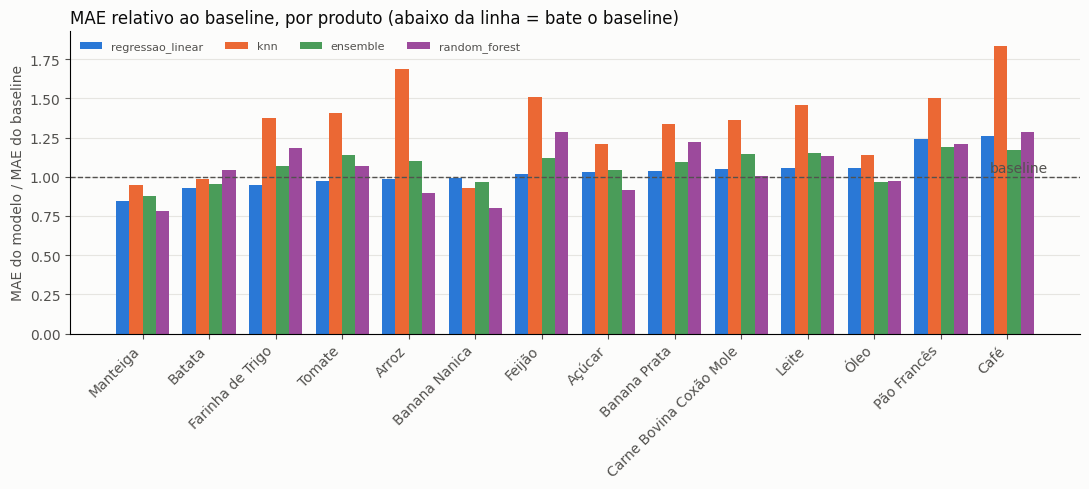

In [6]:
CORES_MODELO = {
    "regressao_linear": "#2a78d6",
    "knn": "#eb6834",
    "ensemble": "#4a9c59",
    "random_forest": "#9c4a9c",
}
TEXTO, TEXTO_2 = "#0b0b0b", "#52514e"
modelos_oficiais = list(CORES_MODELO)

relativo = pivot_mae[modelos_oficiais].div(pivot_mae["baseline"], axis=0).sort_values("regressao_linear")

fig, eixo = plt.subplots(figsize=(11, 5), facecolor="#fcfcfb")
eixo.set_facecolor("#fcfcfb")
x = np.arange(len(relativo))
largura = 0.8 / len(modelos_oficiais)
for i, modelo in enumerate(modelos_oficiais):
    deslocamento = (i - (len(modelos_oficiais) - 1) / 2) * largura
    eixo.bar(x + deslocamento, relativo[modelo], width=largura, color=CORES_MODELO[modelo], label=modelo)
eixo.axhline(1.0, color=TEXTO_2, linewidth=1, linestyle="--")
eixo.text(len(relativo) - 0.4, 1.03, "baseline", ha="right", color=TEXTO_2)
eixo.set_xticks(x, relativo.index, rotation=45, ha="right")
eixo.set_ylabel("MAE do modelo / MAE do baseline", color=TEXTO_2)
eixo.set_title("MAE relativo ao baseline, por produto (abaixo da linha = bate o baseline)", loc="left", color=TEXTO)
eixo.tick_params(colors=TEXTO_2)
eixo.grid(axis="y", color="#e6e5e1", linewidth=0.8)
eixo.set_axisbelow(True)
for lado in ("top", "right"):
    eixo.spines[lado].set_visible(False)
eixo.legend(loc="upper left", ncol=4, frameon=False, fontsize=8, labelcolor=TEXTO_2)
fig.tight_layout()
fig.savefig(config.DIR_FIGURAS / "04_mae_relativo_baseline.png", dpi=150, facecolor=fig.get_facecolor())
plt.show()

### Random Forest e Gradient Boosting não extrapolam

Decisão 6: árvores preveem pela média de valores vistos no treino, então não
conseguem prever acima do maior preço já visto. Em produtos com tendência de
alta, isso faz Random Forest e Gradient Boosting subestimarem o teste por um
motivo estrutural, não por falta de padrão nos dados. A tabela abaixo mostra,
por produto, se o preço máximo do teste passou do máximo do treino.

In [7]:
tabela_extrapolacao = pd.DataFrame(linhas_extrapolacao)
tabela_extrapolacao.to_csv(config.DIR_TABELAS / "04_q1_extrapolacao.csv", index=False)
tabela_extrapolacao

,produto,max_alvo_treino,max_alvo_teste,extrapola
0,Café,73.980000,72.68000,False
1,Arroz,6.958000,5.66800,False
2,Feijão,9.935000,10.32000,True
3,Leite,5.790000,5.99000,True
4,Manteiga,77.700000,75.47500,False
5,Farinha de Trigo,6.540000,5.99000,False
6,Óleo,9.711111,9.68335,False
7,Açúcar,4.790000,4.91500,True
8,Tomate,13.945000,13.39500,False
9,Batata,11.990000,9.99000,False


## Conclusão

Nenhum modelo bate o baseline na maioria dos 14 produtos — a **regressão linear** é a que mais se aproxima, batendo em **6 de 14** (Arroz, Banana Nanica, Batata, Farinha de Trigo, Manteiga, Tomate), seguida por Random Forest e Gradient Boosting (5 de 14 cada), ensemble (4 de 14) e KNN (3 de 14). Isso é consistente com a Q1 estar perto do limite do que ~36 meses de treino por produto permitem prever: o preço do mês seguinte, para a maior parte destes 14 produtos, é melhor estimado pelo preço atual do que por qualquer um dos modelos testados.

A regressão linear se destacar mais aqui do que em versões anteriores (onde todos os modelos usavam o mesmo `n_lags`, escolhido para o KNN) mostra que parte do desempenho fraco dos modelos mais simples vinha de usar entradas pensadas para outro modelo (pendência 2) — não necessariamente de o problema ser imprevisível para qualquer abordagem.

Random Forest e Gradient Boosting têm a limitação estrutural de não extrapolar além do maior preço visto no treino (tabela acima); em metade dos produtos (Feijão, Leite, Açúcar, Banana Nanica, Carne Bovina Coxão Mole, Pão Francês) o teste passou desse máximo, o que tende a piorar o erro desses dois modelos especificamente nesses casos, por motivo estrutural e não por falta de padrão nos dados.

Essa é uma conclusão negativa válida (não um fracasso da análise): com só 48 meses de histórico, é esperado que o preço de boa parte destes produtos seja difícil de prever no curto prazo além do "o preço continua parecido com o de hoje". Narrativa completa em `docs/previsao_q1.md`; tabelas em `reports/tables/04_q1_resultados.csv` e `04_q1_extrapolacao.csv`; figura em `reports/figures/04_mae_relativo_baseline.png`.